# Proyecto integral: predicción del riesgo de desnutrición infantil en Ecuador

**Competencia:** Ecuador Infant Malnutrition Competition – IISEM 2026 MCD  
**Contenido:** análisis exploratorio, preparación de datos, comparación de clasificadores, evaluación y entrega en Kaggle.

Este documento reúne los dos notebooks originales, manteniendo sus celdas de código, resultados y gráficos guardados.

---

# Parte I. Análisis exploratorio y experimentos iniciales

*Contenido original de `01_Analisis_Exploratorio.ipynb`.*

# Predicción del riesgo de desnutrición infantil en Ecuador

**Competencia:** Kaggle – IISEM 2026 MCD

**Objetivo:** Desarrollar un modelo de clasificación que permita predecir el riesgo de desnutrición en niños menores de dos años, utilizando datos sintéticos demográficos, antropométricos y socioeconómicos.

## 1. Carga y exploración de datos

Se importan los conjuntos de entrenamiento y prueba para identificar su estructura, dimensiones y variables disponibles.

In [1]:
import pandas as pd

# Cargar archivos de Kaggle
X_train = pd.read_csv("X_train_Kaggle.csv")
y_train = pd.read_csv("y_train_Kaggle.csv")
X_test = pd.read_csv("X_test_Kaggle.csv")

# Conocer las dimensiones
print("Entrenamiento:", X_train.shape)
print("Variable objetivo:", y_train.shape)
print("Prueba:", X_test.shape)

# Mostrar los primeros 5 registros
display(X_train.head())

Entrenamiento: (70000, 6)
Variable objetivo: (70000, 1)
Prueba: (30000, 6)


,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm
0,0,F,Costa,Secundaria,2.243466,47.340072
1,11,M,Insular,Secundaria,6.157203,67.525274
2,22,M,Costa,Superior,9.781251,86.664662
3,4,F,Sierra,Primaria,2.972311,61.071857
4,-4,F,Costa,Primaria,NaN,50.898250


### Resultados iniciales

Se identificaron 70.000 registros de entrenamiento y 30.000 de prueba, con seis variables predictoras. La revisión inicial evidencia valores faltantes y edades inconsistentes que requieren tratamiento.

## 2. Análisis de calidad de datos

Se revisan los tipos de variables, estadísticas descriptivas y valores faltantes para detectar posibles inconsistencias antes del entrenamiento.

In [2]:

# Información general del conjunto de datos
print("INFORMACIÓN GENERAL")
X_train.info()

# Estadísticas descriptivas
print("\nESTADÍSTICAS DESCRIPTIVAS")
display(X_train.describe(include="all"))

# Identificación de valores faltantes
print("\nVALORES FALTANTES")
faltantes = pd.DataFrame({
    "Cantidad": X_train.isnull().sum(),
    "Porcentaje (%)": (X_train.isnull().mean() * 100).round(2)
})

display(faltantes)

INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   edad_meses             70000 non-null  int64  
 1   sexo                   70000 non-null  object 
 2   region                 70000 non-null  object 
 3   nivel_educacion_madre  70000 non-null  object 
 4   peso_kg                66531 non-null  float64
 5   talla_cm               62951 non-null  float64
dtypes: float64(2), int64(1), object(3)
memory usage: 3.2+ MB

ESTADÍSTICAS DESCRIPTIVAS


,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm
count,70000.000000,70000,70000,70000,66531.000000,62951.000000
unique,NaN,2,4,4,NaN,NaN
top,NaN,F,Amazonía,Secundaria,NaN,NaN
freq,NaN,35185,17606,31488,NaN,NaN
mean,11.459457,NaN,NaN,NaN,6.879973,67.480033
std,8.252734,NaN,NaN,NaN,4.648722,11.937076
min,-12.000000,NaN,NaN,NaN,-0.814205,34.904595
25%,5.000000,NaN,NaN,NaN,4.500895,57.442414
50%,11.000000,NaN,NaN,NaN,6.523145,67.381530
75%,18.000000,NaN,NaN,NaN,8.548997,77.444691



VALORES FALTANTES


,Cantidad,Porcentaje (%)
edad_meses,0,0.00
sexo,0,0.00
region,0,0.00
nivel_educacion_madre,0,0.00
peso_kg,3469,4.96
talla_cm,7049,10.07


### 2.1. Hallazgos principales

Se identificaron valores faltantes en `peso_kg` (4,96 %) y `talla_cm` (10,07 %). Además, existen edades fuera del rango esperado de 0 a 23 meses, pesos negativos y valores extremos.

Estos resultados evidencian la necesidad de analizar las inconsistencias antes de preparar los datos para el entrenamiento.

## 3. Identificación de inconsistencias

Se cuantifican las edades fuera del rango esperado, los pesos y tallas no válidos y los registros duplicados para evaluar la calidad de la información.

In [3]:

# Identificar inconsistencias
print("ANÁLISIS DE INCONSISTENCIAS")

print("Edades negativas:",
      (X_train["edad_meses"] < 0).sum())

print("Edades mayores a 23 meses:",
      (X_train["edad_meses"] > 23).sum())

print("Pesos menores o iguales a cero:",
      (X_train["peso_kg"] <= 0).sum())

print("Tallas menores o iguales a cero:",
      (X_train["talla_cm"] <= 0).sum())

print("Registros duplicados:",
      X_train.duplicated().sum())


ANÁLISIS DE INCONSISTENCIAS
Edades negativas: 3921
Edades mayores a 23 meses: 3792
Pesos menores o iguales a cero: 11
Tallas menores o iguales a cero: 0
Registros duplicados: 100


### 3.1. Resultados del análisis

Se identificaron 7.713 registros con edades fuera del rango esperado, 11 pesos no válidos y 100 registros duplicados en las variables predictoras.

Estas inconsistencias requieren tratamiento antes del entrenamiento, procurando conservar la mayor cantidad posible de información.

## 4. Análisis exploratorio de datos (EDA)

Se analiza la distribución de las variables para identificar patrones, concentraciones y posibles valores atípicos.

### 4.1. Distribución de edades

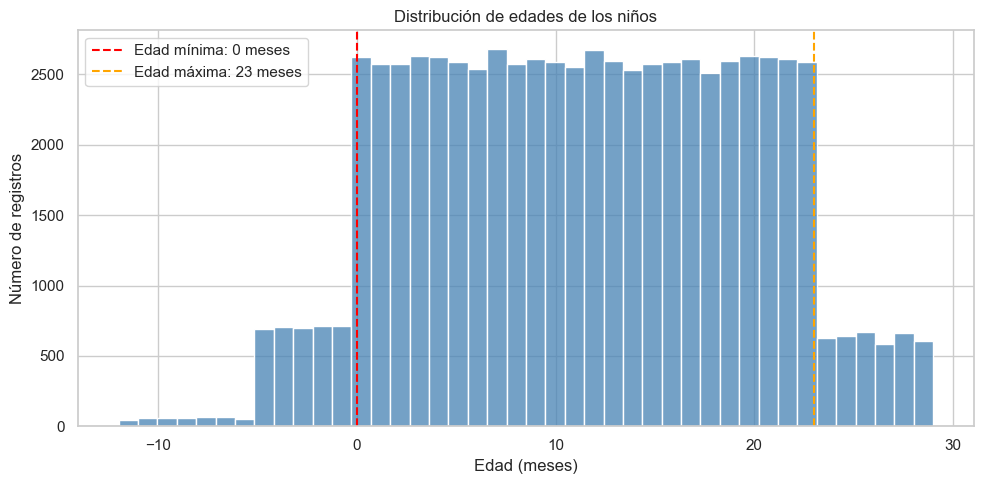

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo
sns.set_theme(style="whitegrid")

# Distribución de edades
plt.figure(figsize=(10, 5))

sns.histplot(
    data=X_train,
    x="edad_meses",
    bins=42,
    color="steelblue"
)

# Límites esperados de edad
plt.axvline(0, color="red", linestyle="--",
            label="Edad mínima: 0 meses")

plt.axvline(23, color="orange", linestyle="--",
            label="Edad máxima: 23 meses")

plt.title("Distribución de edades de los niños")
plt.xlabel("Edad (meses)")
plt.ylabel("Número de registros")
plt.legend()

plt.tight_layout()
plt.show()


**Interpretación:** La mayoría de los registros se concentra entre 0 y 23 meses, con una distribución relativamente uniforme. Sin embargo, el 11,02 % presenta edades fuera del rango esperado, lo que evidencia inconsistencias que deberán tratarse antes del entrenamiento.

### 4.2. Distribución de peso y talla

Se examina la distribución de las variables antropométricas para identificar posibles valores atípicos e inconsistencias.

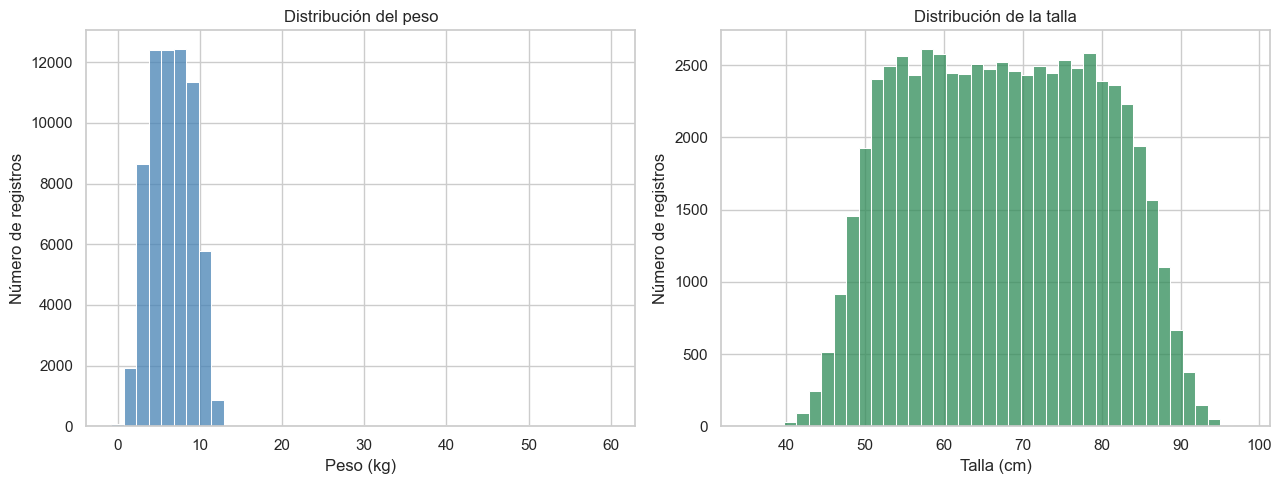

In [5]:

# Distribución del peso y la talla
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Peso
sns.histplot(
    data=X_train,
    x="peso_kg",
    bins=40,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribución del peso")
axes[0].set_xlabel("Peso (kg)")
axes[0].set_ylabel("Número de registros")

# Talla
sns.histplot(
    data=X_train,
    x="talla_cm",
    bins=40,
    color="seagreen",
    ax=axes[1]
)

axes[1].set_title("Distribución de la talla")
axes[1].set_xlabel("Talla (cm)")
axes[1].set_ylabel("Número de registros")

plt.tight_layout()
plt.show()


**Interpretación:** El peso se concentra principalmente entre 2 y 12 kg, aunque presenta valores extremos. La talla muestra una distribución más amplia, con mayor concentración entre 50 y 85 cm. Ambas variables requieren revisión antes del entrenamiento del modelo.

### 4.3. Distribución de la variable objetivo

Se analiza la proporción de registros con y sin riesgo de desnutrición para identificar posibles desequilibrios entre las clases.

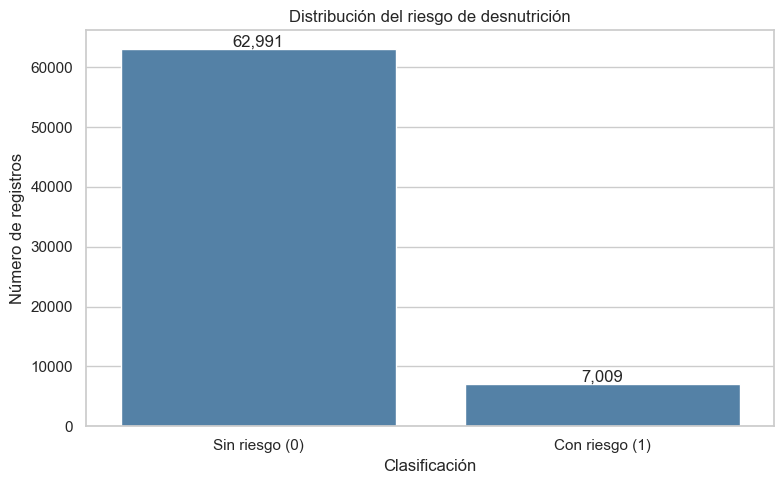

Distribución porcentual:
alerta_desnutricion
0    89.99
1    10.01
Name: count, dtype: float64


In [6]:

# Distribución de la variable objetivo
objetivo = y_train.iloc[:, 0]

conteo = objetivo.value_counts().sort_index()

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=objetivo,
    order=[0, 1],
    color="steelblue"
)

# Mostrar cantidades sobre las barras
for barra in ax.patches:
    cantidad = int(barra.get_height())
    ax.annotate(
        f"{cantidad:,}",
        (barra.get_x() + barra.get_width()/2,
         barra.get_height()),
        ha="center",
        va="bottom"
    )

plt.title("Distribución del riesgo de desnutrición")
plt.xlabel("Clasificación")
plt.ylabel("Número de registros")
plt.xticks([0, 1], ["Sin riesgo (0)", "Con riesgo (1)"])

plt.tight_layout()
plt.show()

# Porcentajes
print("Distribución porcentual:")
print((conteo / conteo.sum() * 100).round(2))


**Interpretación:** El conjunto de datos presenta un desbalance de clases: el 89,99 % corresponde a niños sin riesgo y el 10,01 % a niños con riesgo de desnutrición. Este desequilibrio deberá considerarse durante el entrenamiento y la evaluación de los modelos.

### 4.4. Riesgo de desnutrición por región

Se compara la proporción de registros con riesgo de desnutrición entre las regiones del Ecuador para identificar posibles diferencias geográficas.

,mean,sum,count,porcentaje
region,,,,
Sierra,0.13,2250,17363,12.96
Insular,0.13,2246,17497,12.84
Costa,0.13,2194,17534,12.51
Amazonía,0.02,319,17606,1.81


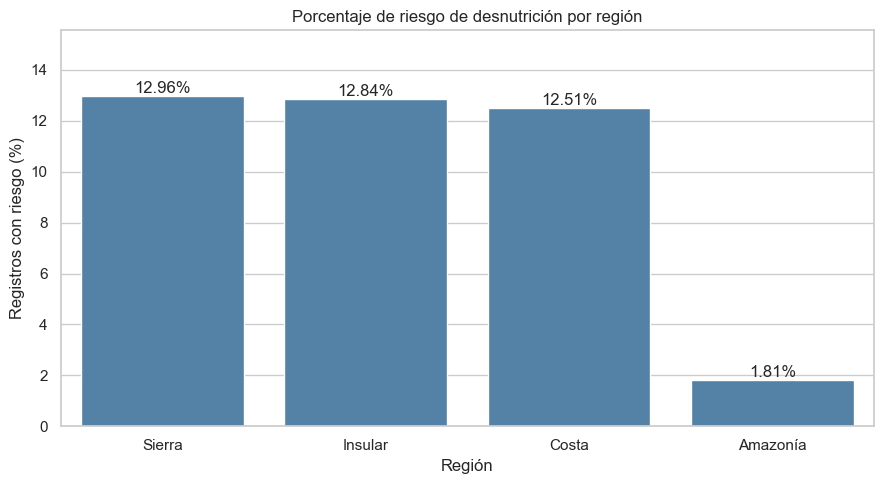

In [7]:

# Unir variables predictoras y objetivo para análisis
df_eda = X_train.copy()
df_eda["alerta_desnutricion"] = y_train.iloc[:, 0].values

# Calcular porcentaje de riesgo por región
riesgo_region = (
    df_eda.groupby("region")["alerta_desnutricion"]
    .agg(["mean", "sum", "count"])
    .sort_values("mean", ascending=False)
)

riesgo_region["porcentaje"] = riesgo_region["mean"] * 100

display(riesgo_region.round(2))

# Gráfico del porcentaje de riesgo
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=riesgo_region.reset_index(),
    x="region",
    y="porcentaje",
    color="steelblue"
)

for barra in ax.patches:
    valor = barra.get_height()
    ax.annotate(
        f"{valor:.2f}%",
        (barra.get_x() + barra.get_width()/2, valor),
        ha="center",
        va="bottom"
    )

plt.title("Porcentaje de riesgo de desnutrición por región")
plt.xlabel("Región")
plt.ylabel("Registros con riesgo (%)")
plt.ylim(0, riesgo_region["porcentaje"].max() * 1.2)

plt.tight_layout()
plt.show()


**Interpretación:** Sierra (12,96 %), Insular (12,84 %) y Costa (12,51 %) presentan proporciones de riesgo similares, mientras que Amazonía registra un 1,81 %. Estas diferencias sugieren que la región podría aportar información relevante al modelo predictivo.

### 4.5. Riesgo de desnutrición según educación de la madre

Se compara el porcentaje de riesgo de desnutrición entre los diferentes niveles educativos de la madre para identificar posibles asociaciones.

,mean,sum,count,porcentaje
nivel_educacion_madre,,,,
Primaria,0.11,2604,24584,10.59
Secundaria,0.11,3313,31488,10.52
Superior,0.10,1089,10491,10.38
Sin escolaridad,0.00,3,3437,0.09


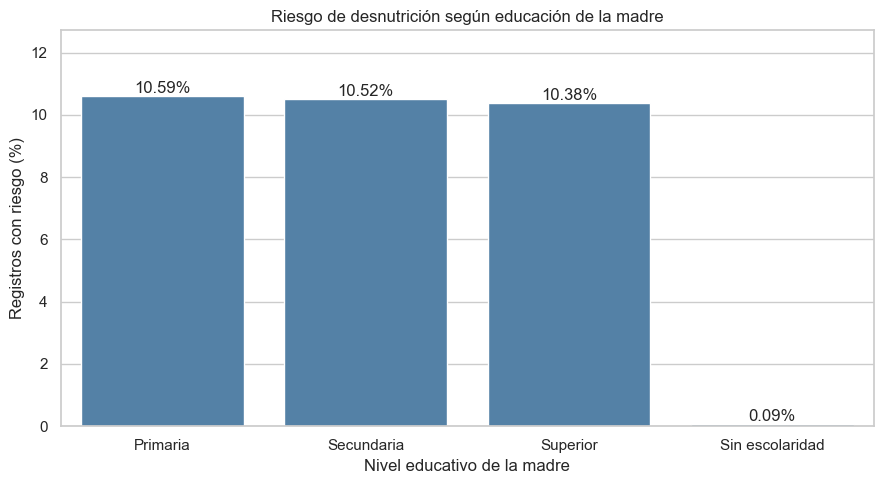

In [8]:

# Riesgo según nivel educativo de la madre
riesgo_educacion = (
    df_eda.groupby("nivel_educacion_madre")["alerta_desnutricion"]
    .agg(["mean", "sum", "count"])
    .sort_values("mean", ascending=False)
)

riesgo_educacion["porcentaje"] = (
    riesgo_educacion["mean"] * 100
)

display(riesgo_educacion.round(2))

# Visualización
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=riesgo_educacion.reset_index(),
    x="nivel_educacion_madre",
    y="porcentaje",
    color="steelblue"
)

for barra in ax.patches:
    valor = barra.get_height()
    ax.annotate(
        f"{valor:.2f}%",
        (barra.get_x() + barra.get_width()/2, valor),
        ha="center",
        va="bottom"
    )

plt.title("Riesgo de desnutrición según educación de la madre")
plt.xlabel("Nivel educativo de la madre")
plt.ylabel("Registros con riesgo (%)")
plt.ylim(0, riesgo_educacion["porcentaje"].max() * 1.2)

plt.tight_layout()
plt.show()


**Interpretación:** Los niveles de educación primaria, secundaria y superior presentan proporciones de riesgo similares, cercanas al 10,5 %. Sin escolaridad registra apenas un 0,09 %, una diferencia marcada que podría reflejar particularidades de los datos sintéticos.

### 4.6. Riesgo de desnutrición según el sexo

Se compara la proporción de riesgo entre niños y niñas para identificar posibles diferencias en la clasificación.

,mean,sum,count,porcentaje
sexo,,,,
F,0.1,3531,35185,10.04
M,0.1,3478,34815,9.99


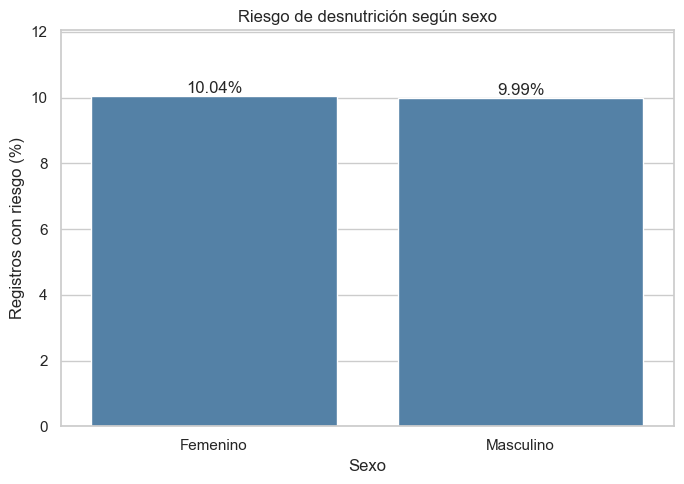

In [9]:

# Riesgo de desnutrición según sexo
riesgo_sexo = (
    df_eda.groupby("sexo")["alerta_desnutricion"]
    .agg(["mean", "sum", "count"])
    .sort_values("mean", ascending=False)
)

riesgo_sexo["porcentaje"] = riesgo_sexo["mean"] * 100

display(riesgo_sexo.round(2))

# Visualización
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=riesgo_sexo.reset_index(),
    x="sexo",
    y="porcentaje",
    color="steelblue"
)

for barra in ax.patches:
    valor = barra.get_height()
    ax.annotate(
        f"{valor:.2f}%",
        (barra.get_x() + barra.get_width()/2, valor),
        ha="center",
        va="bottom"
    )

plt.title("Riesgo de desnutrición según sexo")
plt.xlabel("Sexo")
plt.ylabel("Registros con riesgo (%)")
plt.xticks([0, 1], [
    "Femenino" if s == "F" else "Masculino"
    for s in riesgo_sexo.index
])
plt.ylim(0, riesgo_sexo["porcentaje"].max() * 1.2)

plt.tight_layout()
plt.show()


**Interpretación:** El riesgo de desnutrición presenta proporciones similares entre niñas (10,04 %) y niños (9,99 %). No se observan diferencias relevantes por sexo en el análisis individual.

### 4.7. Relación del peso y la talla con el riesgo de desnutrición

Se comparan las distribuciones de peso y talla entre los registros con y sin riesgo de desnutrición mediante diagramas de caja.

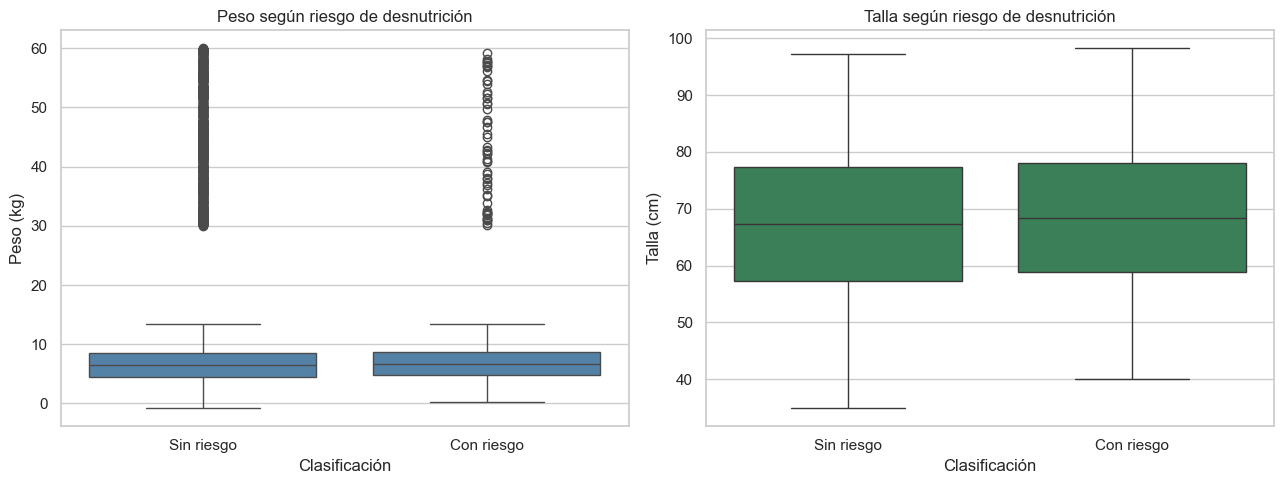

In [10]:

# Comparación de peso y talla según riesgo
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Peso según riesgo
sns.boxplot(
    data=df_eda,
    x="alerta_desnutricion",
    y="peso_kg",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Peso según riesgo de desnutrición")
axes[0].set_xlabel("Clasificación")
axes[0].set_ylabel("Peso (kg)")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Sin riesgo", "Con riesgo"])

# Talla según riesgo
sns.boxplot(
    data=df_eda,
    x="alerta_desnutricion",
    y="talla_cm",
    color="seagreen",
    ax=axes[1]
)

axes[1].set_title("Talla según riesgo de desnutrición")
axes[1].set_xlabel("Clasificación")
axes[1].set_ylabel("Talla (cm)")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Sin riesgo", "Con riesgo"])

plt.tight_layout()
plt.show()


**Interpretación:** Las distribuciones de peso y talla son similares entre los grupos con y sin riesgo. Se identifican valores atípicos importantes en el peso. Estos resultados sugieren analizar ambas variables conjuntamente con la edad.

### 4.8. Relación entre edad, peso y talla

Se analiza cómo varían el peso y la talla según la edad, diferenciando los registros con y sin riesgo de desnutrición.

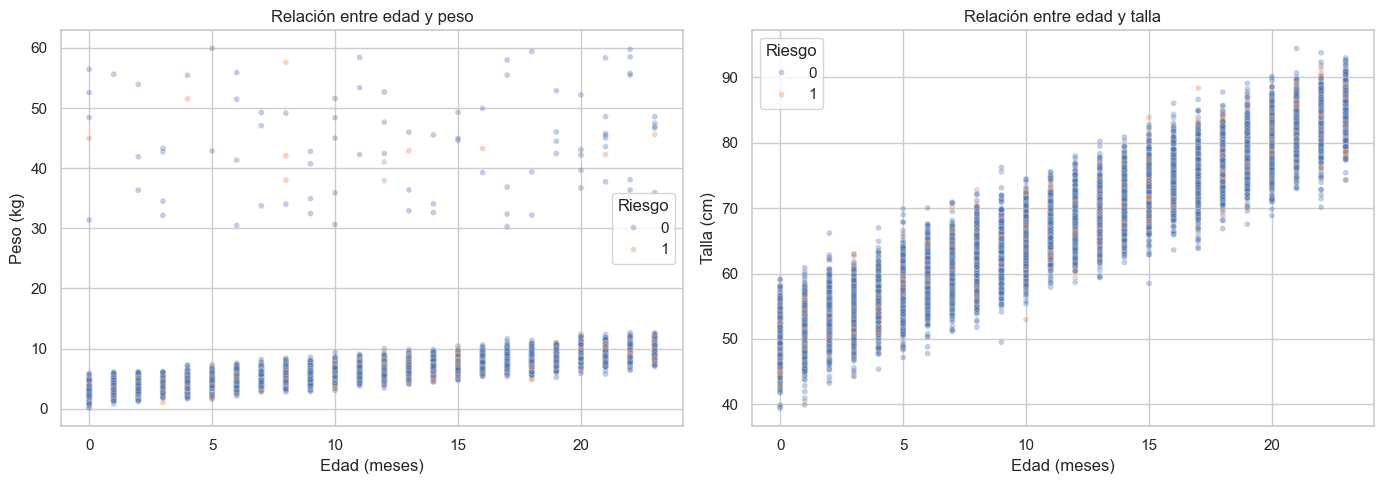

In [11]:

# Seleccionar registros válidos para visualización
df_visual = df_eda[
    df_eda["edad_meses"].between(0, 23) &
    (df_eda["peso_kg"] > 0) &
    (df_eda["talla_cm"] > 0)
].copy()

# Muestra para facilitar la visualización
df_visual = df_visual.sample(
    n=min(10000, len(df_visual)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Edad y peso
sns.scatterplot(
    data=df_visual,
    x="edad_meses",
    y="peso_kg",
    hue="alerta_desnutricion",
    alpha=0.35,
    s=18,
    ax=axes[0]
)

axes[0].set_title("Relación entre edad y peso")
axes[0].set_xlabel("Edad (meses)")
axes[0].set_ylabel("Peso (kg)")
axes[0].legend(title="Riesgo")

# Edad y talla
sns.scatterplot(
    data=df_visual,
    x="edad_meses",
    y="talla_cm",
    hue="alerta_desnutricion",
    alpha=0.35,
    s=18,
    ax=axes[1]
)

axes[1].set_title("Relación entre edad y talla")
axes[1].set_xlabel("Edad (meses)")
axes[1].set_ylabel("Talla (cm)")
axes[1].legend(title="Riesgo")

plt.tight_layout()
plt.show()


**Interpretación:** El peso y la talla presentan una relación positiva con la edad. Se identifican valores extremos en el peso y una superposición considerable entre los grupos con y sin riesgo, lo que sugiere evaluar combinaciones de variables para mejorar la predicción.

## 5. Conclusiones del análisis exploratorio

El conjunto de datos presenta desbalance entre las clases, valores faltantes en peso y talla, edades inconsistentes y valores antropométricos extremos.

Se identificaron diferencias en la proporción de riesgo según la región y el nivel educativo de la madre, mientras que el sexo presenta proporciones similares entre ambos grupos.

Estos hallazgos orientarán la limpieza, transformación y selección de variables para el entrenamiento de los modelos predictivos.

## 6. Preparación de datos

Se divide el conjunto de entrenamiento en un 80 % para entrenar los modelos y un 20 % para evaluar su desempeño, manteniendo la proporción de las clases.

In [12]:

from sklearn.model_selection import train_test_split

# Variables predictoras y variable objetivo
X = X_train.copy()
y = y_train.iloc[:, 0]

# División estratificada: 80 % entrenamiento y 20 % validación
X_entrenamiento, X_validacion, y_entrenamiento, y_validacion = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verificar dimensiones
print("Entrenamiento:", X_entrenamiento.shape)
print("Validación:", X_validacion.shape)

# Verificar proporción de riesgo
print("\nRiesgo en entrenamiento:",
      round(y_entrenamiento.mean() * 100, 2), "%")

print("Riesgo en validación:",
      round(y_validacion.mean() * 100, 2), "%")


Entrenamiento: (56000, 6)
Validación: (14000, 6)

Riesgo en entrenamiento: 10.01 %
Riesgo en validación: 10.01 %


**Interpretación:** Los datos se dividieron en 56.000 registros de entrenamiento y 14.000 de validación. La estratificación mantuvo el 10,01 % de casos con riesgo en ambos conjuntos.

### 6.1. Tratamiento de inconsistencias

Se identifican edades fuera del rango esperado y pesos no válidos, convirtiéndolos en valores faltantes para su posterior imputación.

In [13]:

import numpy as np

# Crear copias para conservar los datos originales
X_entrenamiento_limpio = X_entrenamiento.copy()
X_validacion_limpio = X_validacion.copy()
X_test_limpio = X_test.copy()

# Aplicar las mismas reglas a los tres conjuntos
for df in [
    X_entrenamiento_limpio,
    X_validacion_limpio,
    X_test_limpio
]:
    # Edades fuera del rango esperado
    df.loc[
        ~df["edad_meses"].between(0, 23),
        "edad_meses"
    ] = np.nan

    # Pesos menores o iguales a cero
    df.loc[
        df["peso_kg"] <= 0,
        "peso_kg"
    ] = np.nan

    # Tallas menores o iguales a cero
    df.loc[
        df["talla_cm"] <= 0,
        "talla_cm"
    ] = np.nan

# Verificar valores faltantes después de la limpieza
print("VALORES FALTANTES - ENTRENAMIENTO")
display(X_entrenamiento_limpio.isnull().sum())

print("\nVALORES FALTANTES - VALIDACIÓN")
display(X_validacion_limpio.isnull().sum())


VALORES FALTANTES - ENTRENAMIENTO


edad_meses               6199
sexo                        0
region                      0
nivel_educacion_madre       0
peso_kg                  2813
talla_cm                 5658
dtype: int64


VALORES FALTANTES - VALIDACIÓN


edad_meses               1514
sexo                        0
region                      0
nivel_educacion_madre       0
peso_kg                   667
talla_cm                 1391
dtype: int64

**Interpretación:** La limpieza permitió identificar valores faltantes en edad, peso y talla, incluyendo registros con datos inconsistentes. Se conservaron todas las observaciones para su posterior imputación.

### 6.2. Imputación y transformación de variables

Se aplica imputación por mediana, estandarización de variables numéricas y codificación One-Hot para preparar los datos mediante un pipeline reproducible.

In [14]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Variables numéricas y categóricas
numericas = ["edad_meses", "peso_kg", "talla_cm"]
categoricas = ["sexo", "region", "nivel_educacion_madre"]

# Pipeline para variables numéricas
pipeline_numerico = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

# Pipeline para variables categóricas
pipeline_categorico = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Unir las transformaciones
preprocesador = ColumnTransformer([
    ("numericas", pipeline_numerico, numericas),
    ("categoricas", pipeline_categorico, categoricas)
])

print("Pipeline de preprocesamiento creado correctamente.")


Pipeline de preprocesamiento creado correctamente.


## 7. Entrenamiento de modelos predictivos

### 7.1. Regresión logística

Se entrena un modelo de regresión logística como referencia inicial para predecir el riesgo de desnutrición infantil y evaluar su desempeño sobre los datos de validación.

In [15]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Pipeline completo: preprocesamiento + modelo
modelo_logistico = Pipeline([
    ("preprocesamiento", preprocesador),
    ("modelo", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Entrenar el modelo
modelo_logistico.fit(
    X_entrenamiento_limpio,
    y_entrenamiento
)

# Realizar predicciones sobre validación
y_pred_logistico = modelo_logistico.predict(
    X_validacion_limpio
)

print("Modelo de regresión logística entrenado correctamente.")


Modelo de regresión logística entrenado correctamente.


### 7.2. Evaluación del modelo

Se evalúa el desempeño mediante Accuracy, Precision, Recall, F1-score y matriz de confusión, considerando el desbalance existente entre las clases.

RESULTADOS - REGRESIÓN LOGÍSTICA
Accuracy: 0.8999
Precision: 0.0
Recall: 0.0
F1-score: 0.0

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

           0       0.90      1.00      0.95     12598
           1       0.00      0.00      0.00      1402

    accuracy                           0.90     14000
   macro avg       0.45      0.50      0.47     14000
weighted avg       0.81      0.90      0.85     14000



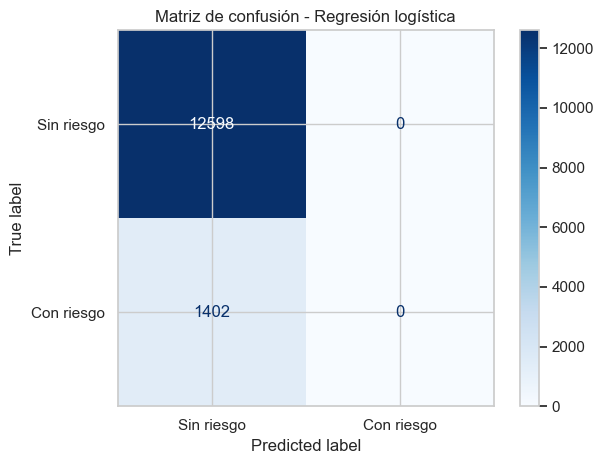

In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calcular métricas
print("RESULTADOS - REGRESIÓN LOGÍSTICA")
print("Accuracy:", round(accuracy_score(y_validacion, y_pred_logistico), 4))
print("Precision:", round(precision_score(y_validacion, y_pred_logistico, zero_division=0), 4))
print("Recall:", round(recall_score(y_validacion, y_pred_logistico, zero_division=0), 4))
print("F1-score:", round(f1_score(y_validacion, y_pred_logistico, zero_division=0), 4))

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(
    y_validacion,
    y_pred_logistico,
    zero_division=0
))

# Matriz de confusión
matriz = confusion_matrix(y_validacion, y_pred_logistico)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Sin riesgo", "Con riesgo"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Regresión logística")
plt.tight_layout()
plt.show()


**Interpretación:** La regresión logística alcanzó un Accuracy del 89,99 %, pero obtuvo Recall y F1-score de 0 % para la clase de riesgo. El modelo clasificó todos los registros como sin riesgo, evidenciando dificultades para identificar la clase minoritaria.

### 7.3. Regresión logística con balanceo de clases

Se incorpora un ajuste de pesos para reducir el efecto del desbalance y mejorar la detección de registros con riesgo de desnutrición.

REGRESIÓN LOGÍSTICA BALANCEADA
Accuracy: 0.3925
Precision: 0.1365
Recall: 0.9515
F1-score: 0.2388


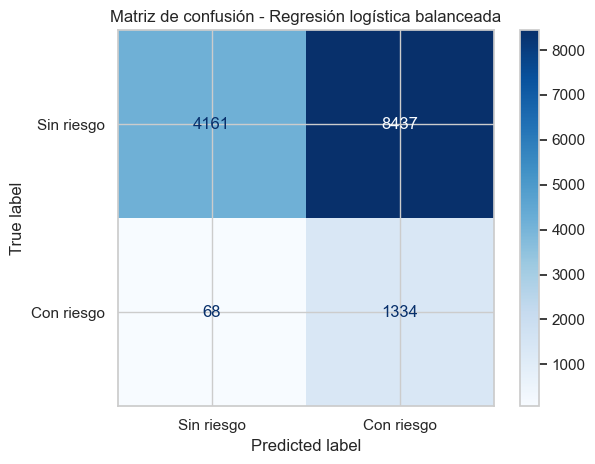

In [17]:

# Regresión logística con pesos balanceados
modelo_logistico_balanceado = Pipeline([
    ("preprocesamiento", preprocesador),
    ("modelo", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Entrenamiento
modelo_logistico_balanceado.fit(
    X_entrenamiento_limpio,
    y_entrenamiento
)

# Predicciones
y_pred_balanceado = modelo_logistico_balanceado.predict(
    X_validacion_limpio
)

# Evaluación
print("REGRESIÓN LOGÍSTICA BALANCEADA")
print("Accuracy:", round(accuracy_score(y_validacion, y_pred_balanceado), 4))
print("Precision:", round(precision_score(y_validacion, y_pred_balanceado, zero_division=0), 4))
print("Recall:", round(recall_score(y_validacion, y_pred_balanceado, zero_division=0), 4))
print("F1-score:", round(f1_score(y_validacion, y_pred_balanceado, zero_division=0), 4))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_validacion,
    y_pred_balanceado,
    display_labels=["Sin riesgo", "Con riesgo"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusión - Regresión logística balanceada")
plt.tight_layout()
plt.show()


**Interpretación:** El balanceo aumentó el Recall del 0 % al 95,15 %, permitiendo identificar 1.334 casos con riesgo. Sin embargo, el Accuracy disminuyó al 39,25 % debido al elevado número de falsos positivos, evidenciando un compromiso entre ambas métricas.

### 7.4. Modelo Random Forest

Se entrena un modelo Random Forest para identificar patrones no lineales y evaluar si mejora la capacidad predictiva respecto a la regresión logística.

RESULTADOS - RANDOM FOREST
Accuracy: 0.8999
Precision: 0.0
Recall: 0.0
F1-score: 0.0


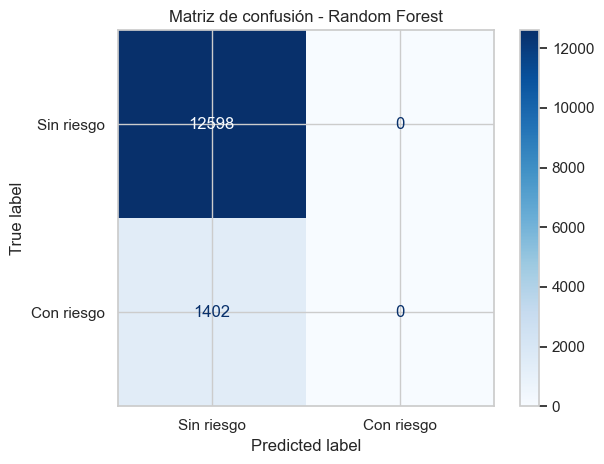

In [18]:

from sklearn.ensemble import RandomForestClassifier

# Pipeline con Random Forest
modelo_rf = Pipeline([
    ("preprocesamiento", preprocesador),
    ("modelo", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenar
modelo_rf.fit(
    X_entrenamiento_limpio,
    y_entrenamiento
)

# Predecir
y_pred_rf = modelo_rf.predict(
    X_validacion_limpio
)

# Evaluar
print("RESULTADOS - RANDOM FOREST")
print("Accuracy:", round(accuracy_score(y_validacion, y_pred_rf), 4))
print("Precision:", round(precision_score(y_validacion, y_pred_rf, zero_division=0), 4))
print("Recall:", round(recall_score(y_validacion, y_pred_rf, zero_division=0), 4))
print("F1-score:", round(f1_score(y_validacion, y_pred_rf, zero_division=0), 4))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_validacion,
    y_pred_rf,
    display_labels=["Sin riesgo", "Con riesgo"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusión - Random Forest")
plt.tight_layout()
plt.show()


**Interpretación:** Random Forest obtuvo un Accuracy del 89,99 %, pero no identificó ningún registro con riesgo de desnutrición. Su comportamiento evidencia que el modelo continúa favoreciendo la clase mayoritaria.

### 7.5. Análisis de probabilidades de predicción

Se examinan las probabilidades generadas por Random Forest para evaluar su capacidad de diferenciar las clases y determinar si el umbral de clasificación influye en los resultados.

PROBABILIDADES - RANDOM FOREST
Mínima: 0.0
Máxima: 0.3804
Promedio: 0.1


,count,mean,std,min,25%,50%,75%,max
Clase real,,,,,,,,
0,12598.0,0.0965,0.0673,0.0,0.0220,0.1090,0.1441,0.3804
1,1402.0,0.1309,0.0491,0.0,0.1044,0.1288,0.1554,0.3507


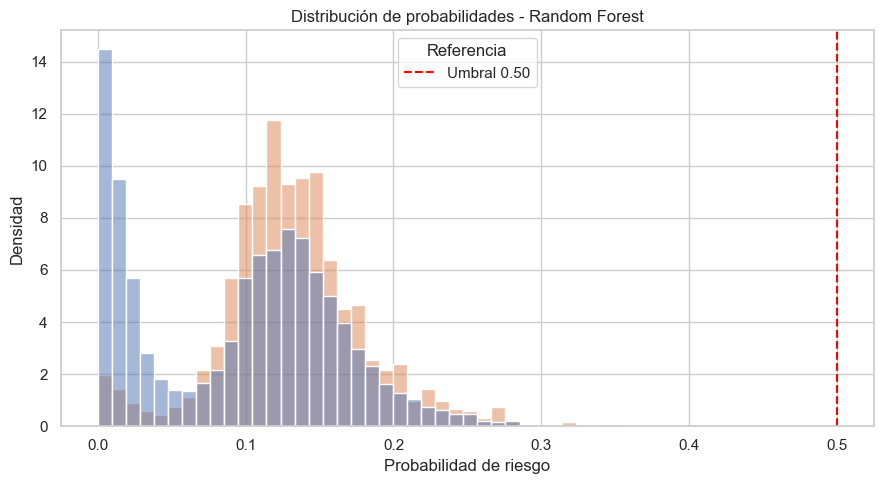

In [19]:

# Probabilidades de pertenecer a la clase 1
probabilidades_rf = modelo_rf.predict_proba(
    X_validacion_limpio
)[:, 1]

# Estadísticas de las probabilidades
print("PROBABILIDADES - RANDOM FOREST")
print("Mínima:", round(probabilidades_rf.min(), 4))
print("Máxima:", round(probabilidades_rf.max(), 4))
print("Promedio:", round(probabilidades_rf.mean(), 4))

# Comparación por clase real
df_probabilidades = pd.DataFrame({
    "Probabilidad": probabilidades_rf,
    "Clase real": y_validacion.values
})

display(
    df_probabilidades.groupby("Clase real")[
        "Probabilidad"
    ].describe().round(4)
)

# Histograma
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_probabilidades,
    x="Probabilidad",
    hue="Clase real",
    bins=40,
    alpha=0.5,
    stat="density",
    common_norm=False
)

plt.axvline(
    0.5,
    color="red",
    linestyle="--",
    label="Umbral 0.50"
)

plt.title("Distribución de probabilidades - Random Forest")
plt.xlabel("Probabilidad de riesgo")
plt.ylabel("Densidad")
plt.legend(
    title="Referencia",
    labels=["Umbral 0.50"]
)

plt.tight_layout()
plt.show()


**Interpretación:** Random Forest genera probabilidades promedio de 9,65 % para la clase 0 y 13,09 % para la clase 1. Ninguna supera el umbral de 0,50, lo que explica la ausencia de predicciones positivas. Se evaluarán diferentes umbrales para analizar su efecto sobre el desempeño.

### 7.6. Evaluación de umbrales de clasificación

Se comparan diferentes umbrales de probabilidad para analizar su impacto sobre Accuracy, Precision, Recall y F1-score.

In [20]:

# Evaluar diferentes umbrales de clasificación
umbrales = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.50]

resultados_umbrales = []

for umbral in umbrales:

    predicciones = (probabilidades_rf >= umbral).astype(int)

    resultados_umbrales.append({
        "Umbral": umbral,
        "Accuracy": accuracy_score(y_validacion, predicciones),
        "Precision": precision_score(
            y_validacion, predicciones, zero_division=0
        ),
        "Recall": recall_score(
            y_validacion, predicciones, zero_division=0
        ),
        "F1-score": f1_score(
            y_validacion, predicciones, zero_division=0
        )
    })

df_umbrales = pd.DataFrame(resultados_umbrales)

display(df_umbrales.round(4))


,Umbral,Accuracy,Precision,Recall,F1-score
0,0.05,0.3916,0.1360,0.9479,0.2379
1,0.10,0.4783,0.1356,0.7832,0.2312
2,0.15,0.7354,0.1316,0.2932,0.1816
3,0.20,0.8617,0.1478,0.0799,0.1037
4,0.25,0.8916,0.1506,0.0178,0.0319
5,0.30,0.8986,0.1304,0.0021,0.0042
6,0.50,0.8999,0.0000,0.0000,0.0000


**Interpretación:** La reducción del umbral incrementó el Recall hasta un 94,79 %, pero disminuyó el Accuracy. El umbral de 0,50 obtuvo la mayor exactitud (89,99 %), aunque sin identificar casos positivos. Se requiere evaluar modelos alternativos.

### 7.7. Modelo HistGradientBoosting

Se entrena un modelo de Gradient Boosting para evaluar si el aprendizaje secuencial permite identificar patrones más complejos y mejorar el desempeño predictivo.

RESULTADOS - HISTGRADIENTBOOSTING
Accuracy: 0.8999
Precision: 0.0
Recall: 0.0
F1-score: 0.0


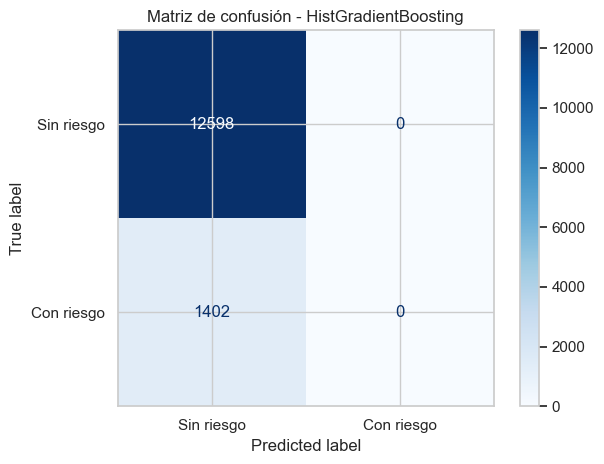

In [21]:

from sklearn.ensemble import HistGradientBoostingClassifier

# Modelo HistGradientBoosting
modelo_hgb = Pipeline([
    ("preprocesamiento", preprocesador),
    ("modelo", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

# Entrenamiento
modelo_hgb.fit(
    X_entrenamiento_limpio,
    y_entrenamiento
)

# Predicciones
y_pred_hgb = modelo_hgb.predict(
    X_validacion_limpio
)

# Evaluación
print("RESULTADOS - HISTGRADIENTBOOSTING")
print("Accuracy:", round(accuracy_score(y_validacion, y_pred_hgb), 4))
print("Precision:", round(precision_score(y_validacion, y_pred_hgb, zero_division=0), 4))
print("Recall:", round(recall_score(y_validacion, y_pred_hgb, zero_division=0), 4))
print("F1-score:", round(f1_score(y_validacion, y_pred_hgb, zero_division=0), 4))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_validacion,
    y_pred_hgb,
    display_labels=["Sin riesgo", "Con riesgo"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusión - HistGradientBoosting")
plt.tight_layout()
plt.show()


**Interpretación:** HistGradientBoosting obtuvo un Accuracy del 89,99 %, pero no identificó casos positivos. Al igual que los modelos anteriores, favoreció la clase mayoritaria, por lo que resulta necesario investigar la importancia de las variables predictoras.

### 7.8. Importancia de las variables predictoras

Se utiliza Permutation Importance para identificar qué variables aportan información al modelo HistGradientBoosting, empleando Average Precision como métrica de evaluación.

,Variable,Importancia
2,region,0.0302
3,nivel_educacion_madre,0.0074
4,peso_kg,0.0026
5,talla_cm,0.0023
0,edad_meses,0.0010
1,sexo,-0.0006


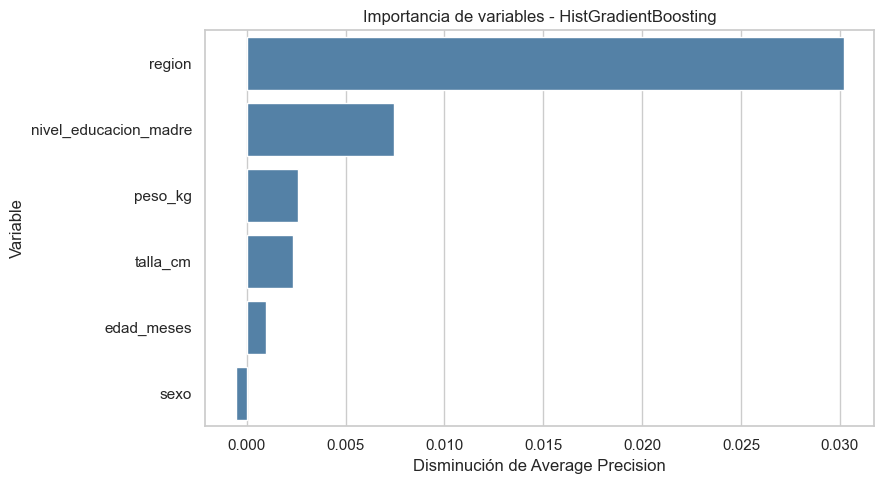

In [22]:

from sklearn.inspection import permutation_importance

# Calcular importancia de las variables
importancias = permutation_importance(
    modelo_hgb,
    X_validacion_limpio,
    y_validacion,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Organizar resultados
df_importancias = pd.DataFrame({
    "Variable": X_validacion_limpio.columns,
    "Importancia": importancias.importances_mean
}).sort_values("Importancia", ascending=False)

display(df_importancias.round(4))

# Visualización
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_importancias,
    x="Importancia",
    y="Variable",
    color="steelblue"
)

plt.title("Importancia de variables - HistGradientBoosting")
plt.xlabel("Disminución de Average Precision")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()


**Interpretación:** La región presenta la mayor importancia predictiva (0,0302), seguida del nivel educativo de la madre (0,0074). Las variables antropométricas muestran contribuciones menores, lo que sugiere explorar nuevas características relacionadas con el crecimiento infantil.

## 8. Ingeniería de características

Se generan nuevas variables a partir de edad, peso y talla para explorar relaciones antropométricas que podrían mejorar la capacidad predictiva del modelo.

In [23]:

# Crear copias de los conjuntos procesados
X_entrenamiento_fe = X_entrenamiento_limpio.copy()
X_validacion_fe = X_validacion_limpio.copy()
X_test_fe = X_test_limpio.copy()

# Aplicar las mismas transformaciones
for df in [
    X_entrenamiento_fe,
    X_validacion_fe,
    X_test_fe
]:
    # Peso dividido entre talla en metros al cuadrado
    df["imc"] = df["peso_kg"] / (df["talla_cm"] / 100) ** 2

    # Peso relativo a la edad
    df["peso_edad"] = df["peso_kg"] / (df["edad_meses"] + 1)

    # Talla relativa a la edad
    df["talla_edad"] = df["talla_cm"] / (df["edad_meses"] + 1)

# Verificar nuevas variables
print("NUEVAS VARIABLES")
display(X_entrenamiento_fe.head())

print("\nDimensiones:", X_entrenamiento_fe.shape)

NUEVAS VARIABLES


,edad_meses,sexo,region,nivel_educacion_madre,peso_kg,talla_cm,imc,peso_edad,talla_edad
30598,12.0,F,Amazonía,Secundaria,6.884285,65.693172,15.952119,0.529560,5.053321
49249,14.0,M,Sierra,Secundaria,8.548875,65.889556,19.691365,0.569925,4.392637
11658,18.0,M,Insular,Secundaria,8.105505,74.699762,14.525853,0.426606,3.931566
27455,19.0,M,Sierra,Primaria,9.448831,77.821049,15.602130,0.472442,3.891052
39061,11.0,M,Insular,Secundaria,7.425414,58.016638,22.060510,0.618784,4.834720



Dimensiones: (56000, 9)


### 8.1. Actualización del preprocesamiento

Se incorporan las tres nuevas variables al pipeline para evaluar su contribución al rendimiento del modelo predictivo.

In [24]:

from sklearn.base import clone

# Variables numéricas originales y nuevas
numericas_fe = [
    "edad_meses",
    "peso_kg",
    "talla_cm",
    "imc",
    "peso_edad",
    "talla_edad"
]

# Variables categóricas
categoricas_fe = [
    "sexo",
    "region",
    "nivel_educacion_madre"
]

# Actualizar el preprocesador
preprocesador_fe = ColumnTransformer([
    ("numericas", clone(pipeline_numerico), numericas_fe),
    ("categoricas", clone(pipeline_categorico), categoricas_fe)
])

print("Preprocesador actualizado correctamente.")
print("Variables numéricas:", len(numericas_fe))
print("Variables categóricas:", len(categoricas_fe))


Preprocesador actualizado correctamente.
Variables numéricas: 6
Variables categóricas: 3


### 8.2. Random Forest con ingeniería de características

Se entrena nuevamente Random Forest incorporando las variables derivadas de peso, talla y edad, para comparar su rendimiento con el modelo original.

RANDOM FOREST - NUEVAS VARIABLES
Accuracy: 0.8999
Precision: 0.0
Recall: 0.0
F1-score: 0.0


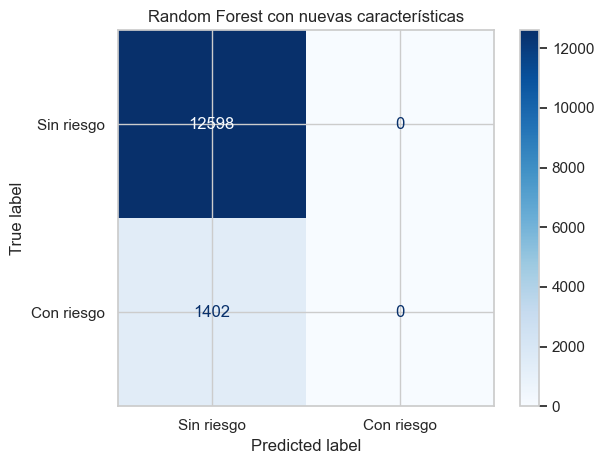

In [25]:

# Random Forest con nuevas características
modelo_rf_fe = Pipeline([
    ("preprocesamiento", preprocesador_fe),
    ("modelo", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Entrenamiento
modelo_rf_fe.fit(
    X_entrenamiento_fe,
    y_entrenamiento
)

# Predicciones
y_pred_rf_fe = modelo_rf_fe.predict(
    X_validacion_fe
)

# Evaluación
print("RANDOM FOREST - NUEVAS VARIABLES")

print("Accuracy:",
      round(accuracy_score(y_validacion, y_pred_rf_fe), 4))

print("Precision:",
      round(precision_score(y_validacion, y_pred_rf_fe, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_validacion, y_pred_rf_fe, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_validacion, y_pred_rf_fe, zero_division=0), 4))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_validacion,
    y_pred_rf_fe,
    display_labels=["Sin riesgo", "Con riesgo"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest con nuevas características")
plt.tight_layout()
plt.show()


**Interpretación:** La incorporación de tres nuevas variables no mejoró el desempeño de Random Forest. El modelo mantuvo un Accuracy del 89,99 %, sin identificar casos positivos, por lo que se requiere explorar otras estrategias de aprendizaje.

### 8.3. Evaluación de la capacidad discriminativa

Se utilizan ROC-AUC y Average Precision para evaluar la capacidad del modelo de diferenciar las clases sin depender de un único umbral de clasificación.

In [26]:

from sklearn.metrics import roc_auc_score, average_precision_score

# Obtener probabilidades de ambos modelos
prob_rf_original = modelo_rf.predict_proba(
    X_validacion_limpio
)[:, 1]

prob_rf_nuevo = modelo_rf_fe.predict_proba(
    X_validacion_fe
)[:, 1]

# Comparar capacidad discriminativa
comparacion = pd.DataFrame({
    "Modelo": [
        "Random Forest original",
        "Random Forest nuevas variables"
    ],
    "ROC-AUC": [
        roc_auc_score(y_validacion, prob_rf_original),
        roc_auc_score(y_validacion, prob_rf_nuevo)
    ],
    "Average Precision": [
        average_precision_score(y_validacion, prob_rf_original),
        average_precision_score(y_validacion, prob_rf_nuevo)
    ]
})

display(comparacion.round(4))


,Modelo,ROC-AUC,Average Precision
0,Random Forest original,0.6379,0.1359
1,Random Forest nuevas variables,0.6455,0.1349


**Interpretación:** La ingeniería de características incrementó ligeramente el ROC-AUC de 0,6379 a 0,6455, mientras que Average Precision disminuyó de 0,1359 a 0,1349. Las nuevas variables no produjeron una mejora consistente del rendimiento.

### 8.4. Interacción entre región y educación de la madre

Se analiza la proporción de riesgo para cada combinación de región y nivel educativo, con el objetivo de identificar patrones conjuntos que podrían contribuir a la predicción.

nivel_educacion_madre,Primaria,Secundaria,Sin escolaridad,Superior
region,,,,
Amazonía,1.91,1.91,0.00,1.86
Costa,13.43,12.99,0.34,13.06
Insular,13.00,14.02,0.00,12.95
Sierra,13.97,13.42,0.00,13.46


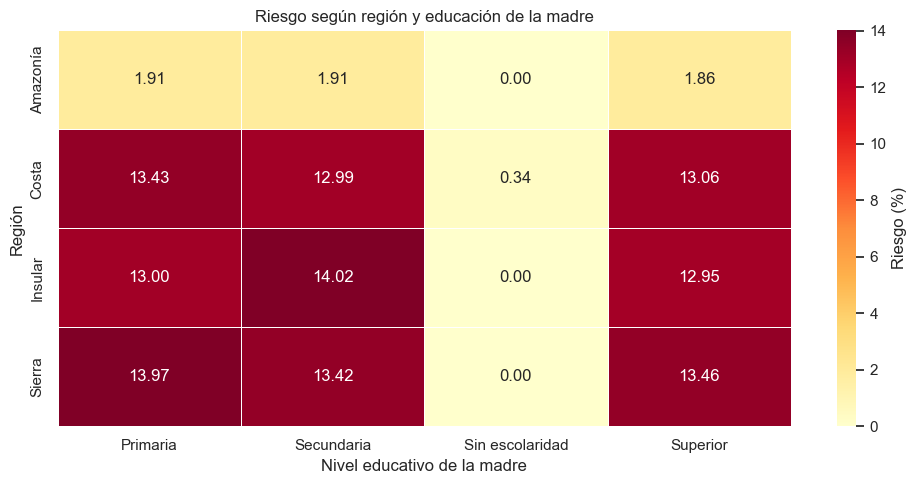

In [27]:

# Tabla de riesgo por región y educación
tabla_interaccion = pd.pivot_table(
    df_eda,
    values="alerta_desnutricion",
    index="region",
    columns="nivel_educacion_madre",
    aggfunc="mean"
) * 100

display(tabla_interaccion.round(2))

# Gráfico de mapa de calor
plt.figure(figsize=(10, 5))

sns.heatmap(
    tabla_interaccion,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Riesgo (%)"}
)

plt.title("Riesgo según región y educación de la madre")
plt.xlabel("Nivel educativo de la madre")
plt.ylabel("Región")

plt.tight_layout()
plt.show()


**Interpretación:** El riesgo presenta diferencias marcadas según la región y el nivel educativo de la madre. Amazonía y la categoría sin escolaridad registran las proporciones más bajas, lo que sugiere patrones relevantes en los datos sintéticos.

### 8.5. Evaluación de variables categóricas

Se evalúa la capacidad predictiva de la región y el nivel educativo de la madre para determinar su contribución individual al modelo de clasificación.

In [28]:

# Seleccionar variables categóricas
variables_cat = ["region", "nivel_educacion_madre"]

# Crear preprocesador específico
preprocesador_cat = ColumnTransformer([
    ("categoricas", OneHotEncoder(handle_unknown="ignore"),
     variables_cat)
])

# Modelo con variables categóricas
modelo_cat = Pipeline([
    ("preprocesamiento", preprocesador_cat),
    ("modelo", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Entrenar
modelo_cat.fit(
    X_entrenamiento_limpio,
    y_entrenamiento
)

# Obtener probabilidades
prob_cat = modelo_cat.predict_proba(
    X_validacion_limpio
)[:, 1]

# Evaluar capacidad discriminativa
print("MODELO CON VARIABLES CATEGÓRICAS")
print("ROC-AUC:", round(
    roc_auc_score(y_validacion, prob_cat), 4
))
print("Average Precision:", round(
    average_precision_score(y_validacion, prob_cat), 4
))
print("Accuracy:", round(
    accuracy_score(
        y_validacion,
        modelo_cat.predict(X_validacion_limpio)
    ), 4
))


MODELO CON VARIABLES CATEGÓRICAS
ROC-AUC: 0.635
Average Precision: 0.1326
Accuracy: 0.8999


**Interpretación:** El modelo basado únicamente en región y educación de la madre obtuvo un ROC-AUC de 0,6350, cercano al 0,6379 de Random Forest. Esto sugiere que ambas variables categóricas concentran una parte importante de la información predictiva disponible.

### 8.6. Análisis de patrones en grupos específicos

Se examinan las relaciones entre edad, peso, talla y riesgo en registros de regiones distintas de Amazonía y con educación materna diferente de sin escolaridad.

In [29]:

# Seleccionar grupos para análisis diagnóstico
df_grupo = df_eda[
    (df_eda["region"] != "Amazonía") &
    (df_eda["nivel_educacion_madre"] != "Sin escolaridad")
].copy()

# Comparación de variables numéricas según riesgo
resumen_grupo = df_grupo.groupby(
    "alerta_desnutricion"
)[["edad_meses", "peso_kg", "talla_cm"]].agg(
    ["mean", "median", "std"]
)

print("COMPARACIÓN DE VARIABLES POR CLASE")
display(resumen_grupo.round(2))

# Correlaciones con la variable objetivo
correlaciones = df_grupo[
    ["edad_meses", "peso_kg", "talla_cm", "alerta_desnutricion"]
].corr()

print("\nCORRELACIONES CON EL RIESGO")
display(
    correlaciones[["alerta_desnutricion"]].round(4)
)


COMPARACIÓN DE VARIABLES POR CLASE


edad_meses              peso_kg              talla_cm  \
                          mean median   std    mean median   std     mean   
alerta_desnutricion                                                         
0                        11.36   11.0  8.30    6.86   6.49  4.69    67.34   
1                        12.13   12.0  7.92    6.98   6.67  4.28    68.45   

                                   
                    median    std  
alerta_desnutricion                
0                    67.26  11.96  
1                    68.29  11.66


CORRELACIONES CON EL RIESGO


,alerta_desnutricion
edad_meses,0.0318
peso_kg,0.0084
talla_cm,0.0316
alerta_desnutricion,1.0000


---

# Parte II. Modelo seleccionado y validación para Kaggle

*Contenido original de `02_Modelo_Final_Kaggle(1).ipynb`.*

**Nota de reproducibilidad:** esta parte vuelve a cargar los CSV y utiliza nombres de variables propios. Ejecútala desde su primera celda para reiniciar correctamente el conjunto de trabajo.

# Predicción del riesgo de desnutrición infantil en Ecuador

**Competencia:** Kaggle – IISEM 2026 MCD

**Objetivo:** Desarrollar y comparar modelos de clasificación supervisada para predecir el riesgo de desnutrición infantil, aplicando técnicas de preprocesamiento, validación y optimización de hiperparámetros.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los datos originales
X = pd.read_csv("X_train_Kaggle.csv")
y = pd.read_csv("y_train_Kaggle.csv")["alerta_desnutricion"]
X_test = pd.read_csv("X_test_Kaggle.csv")
submission = pd.read_csv("sample_submission_malnutrition.csv")

# Verificar estructura
print("Entrenamiento:", X.shape)
print("Variable objetivo:", y.shape)
print("Prueba Kaggle:", X_test.shape)
print("Formato de entrega:", submission.shape)

# Distribución de clases
print("\nDistribución de clases (%)")
print((y.value_counts(normalize=True) * 100).round(2))


Entrenamiento: (70000, 6)
Variable objetivo: (70000,)
Prueba Kaggle: (30000, 6)
Formato de entrega: (30000, 2)

Distribución de clases (%)
alerta_desnutricion
0    89.99
1    10.01
Name: proportion, dtype: float64


## 1. División de los datos

Se reserva el 20 % de los registros para validación final y se utiliza el 80 % restante para entrenamiento y selección de modelos, conservando la proporción de ambas clases.

In [2]:

from sklearn.model_selection import train_test_split

# División estratificada de los datos
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Comprobar dimensiones
print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba Kaggle:", X_test.shape)

# Verificar el balance de clases
print("\nRiesgo en entrenamiento:",
      round(y_train.mean() * 100, 2), "%")

print("Riesgo en validación:",
      round(y_val.mean() * 100, 2), "%")


Entrenamiento: (56000, 6)
Validación: (14000, 6)
Prueba Kaggle: (30000, 6)

Riesgo en entrenamiento: 10.01 %
Riesgo en validación: 10.01 %


## 2. Preprocesamiento de datos

Se construye un pipeline que integra imputación de valores faltantes, estandarización de variables numéricas y codificación de variables categóricas, evitando la fuga de información.

In [3]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identificar variables
numericas = ["edad_meses", "peso_kg", "talla_cm"]

categoricas = [
    "sexo",
    "region",
    "nivel_educacion_madre"
]

# Preparación de variables numéricas
pipeline_numerico = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Preparación de variables categóricas
pipeline_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

# Construir preprocesador
preprocesador = ColumnTransformer([
    ("numericas", pipeline_numerico, numericas),
    ("categoricas", pipeline_categorico, categoricas)
])

print("Pipeline de preprocesamiento creado correctamente.")


Pipeline de preprocesamiento creado correctamente.


## 3. Comparación de modelos de clasificación

Se comparan regresión logística, KNN y árbol de decisión mediante validación cruzada estratificada de tres particiones, utilizando Accuracy, Recall y F1-score.

In [4]:

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

# Modelos iniciales
modelos = {
    "Regresión logística": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    "Árbol de decisión": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=20,
        random_state=42
    )
}

# Validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

resultados = []

for nombre, algoritmo in modelos.items():

    modelo = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", clone(algoritmo))
    ])

    metricas = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "recall": "recall",
            "f1": "f1"
        },
        n_jobs=1
    )

    resultados.append({
        "Modelo": nombre,
        "Accuracy": metricas["test_accuracy"].mean(),
        "Recall": metricas["test_recall"].mean(),
        "F1-score": metricas["test_f1"].mean()
    })

df_resultados = pd.DataFrame(resultados)

display(
    df_resultados.sort_values(
        "Accuracy", ascending=False
    ).round(4)
)


,Modelo,Accuracy,Recall,F1-score
0,Regresión logística,0.8999,0.0000,0.0000
2,Árbol de decisión,0.8999,0.0000,0.0000
1,KNN,0.8998,0.0005,0.0011


**Interpretación:** Los tres modelos obtuvieron un Accuracy cercano al 90 %, pero presentaron dificultades para identificar la clase minoritaria. Se evaluarán estrategias de balanceo y ajuste de parámetros para mejorar la clasificación.

## 4. Balanceo de clases

Se evalúa el efecto de asignar mayor peso a la clase minoritaria mediante regresión logística y árboles de decisión, comparando Accuracy, Recall y F1-score.

In [5]:

# Modelos con balanceo de clases
modelos_balanceados = {
    "Logística balanceada": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Árbol balanceado": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    )
}

resultados_balanceados = []

for nombre, algoritmo in modelos_balanceados.items():

    modelo = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", clone(algoritmo))
    ])

    metricas = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },
        n_jobs=1
    )

    resultados_balanceados.append({
        "Modelo": nombre,
        "Accuracy": metricas["test_accuracy"].mean(),
        "Precision": metricas["test_precision"].mean(),
        "Recall": metricas["test_recall"].mean(),
        "F1-score": metricas["test_f1"].mean()
    })

df_balanceados = pd.DataFrame(resultados_balanceados)

display(df_balanceados.round(4))


,Modelo,Accuracy,Precision,Recall,F1-score
0,Logística balanceada,0.3818,0.1343,0.9504,0.2354
1,Árbol balanceado,0.4238,0.1400,0.9242,0.2431


**Interpretación:** El balanceo incrementó el Recall por encima del 92 %, pero redujo considerablemente el Accuracy. Los resultados evidencian que esta estrategia no mejora la métrica oficial de Kaggle con las configuraciones evaluadas.

## 5. Optimización de hiperparámetros

Se utiliza GridSearchCV con validación cruzada estratificada para identificar la configuración del árbol de decisión que maximiza el Accuracy.

In [6]:

from sklearn.model_selection import GridSearchCV

# Pipeline con árbol de decisión
pipeline_arbol = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("clasificador", DecisionTreeClassifier(
        random_state=42
    ))
])

# Combinaciones de parámetros
parametros_arbol = {
    "clasificador__max_depth": [4, 8, 12, 20, None],
    "clasificador__min_samples_leaf": [1, 5, 20, 50],
    "clasificador__criterion": ["gini", "entropy"]
}

# Búsqueda con validación cruzada
busqueda_arbol = GridSearchCV(
    estimator=pipeline_arbol,
    param_grid=parametros_arbol,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Entrenar y buscar mejores parámetros
busqueda_arbol.fit(X_train, y_train)

# Resultados
print("MEJORES PARÁMETROS")
print(busqueda_arbol.best_params_)

print("\nMEJOR ACCURACY EN VALIDACIÓN CRUZADA")
print(round(busqueda_arbol.best_score_, 4))


Fitting 3 folds for each of 40 candidates, totalling 120 fits
MEJORES PARÁMETROS
{'clasificador__criterion': 'gini', 'clasificador__max_depth': 4, 'clasificador__min_samples_leaf': 5}

MEJOR ACCURACY EN VALIDACIÓN CRUZADA
0.8999


**Interpretación:** GridSearchCV seleccionó un árbol de decisión con profundidad máxima de 4 y un mínimo de 5 registros por hoja. El Accuracy permaneció en 89,99 %, sin superar el modelo de referencia.

## 6. Comparación de estrategias de limpieza

Se evalúa si conservar o corregir valores inconsistentes modifica el rendimiento de la clasificación, utilizando validación cruzada estratificada.

In [7]:

from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import cross_val_score

# Función para tratar inconsistencias
def limpiar_inconsistencias(df):
    df = df.copy()

    df.loc[
        ~df["edad_meses"].between(0, 23),
        "edad_meses"
    ] = np.nan

    df.loc[
        df["peso_kg"] <= 0,
        "peso_kg"
    ] = np.nan

    df.loc[
        df["talla_cm"] <= 0,
        "talla_cm"
    ] = np.nan

    return df

# Estrategia A: conservar valores originales
modelo_original = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("clasificador", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=5,
        random_state=42
    ))
])

# Estrategia B: tratar inconsistencias
modelo_limpio = Pipeline([
    ("limpieza", FunctionTransformer(limpiar_inconsistencias)),
    ("preprocesamiento", clone(preprocesador)),
    ("clasificador", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=5,
        random_state=42
    ))
])

# Comparar resultados
resultados_limpieza = []

for nombre, modelo in [
    ("Datos originales", modelo_original),
    ("Datos corregidos", modelo_limpio)
]:
    scores = cross_val_score(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=1
    )

    resultados_limpieza.append({
        "Estrategia": nombre,
        "Accuracy promedio": scores.mean(),
        "Desviación estándar": scores.std()
    })

display(pd.DataFrame(resultados_limpieza).round(4))


,Estrategia,Accuracy promedio,Desviación estándar
0,Datos originales,0.8999,0.0
1,Datos corregidos,0.8999,0.0


**Interpretación:** Las estrategias con datos originales y corregidos obtuvieron el mismo Accuracy (89,99 %). El tratamiento de inconsistencias no produjo mejoras en el árbol de decisión evaluado.

### 6.1. Capacidad discriminativa según estrategia de limpieza

Se comparan ROC-AUC y Average Precision para determinar si el tratamiento de inconsistencias modifica la capacidad de distinguir las clases.

In [8]:

from sklearn.model_selection import cross_validate

# Comparación utilizando probabilidades
resultados_discriminacion = []

for nombre, modelo in [
    ("Datos originales", modelo_original),
    ("Datos corregidos", modelo_limpio)
]:
    scores = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "average_precision": "average_precision"
        },
        n_jobs=1
    )

    resultados_discriminacion.append({
        "Estrategia": nombre,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Average Precision": scores["test_average_precision"].mean()
    })

display(pd.DataFrame(resultados_discriminacion).round(4))


,Estrategia,ROC-AUC,Average Precision
0,Datos originales,0.6517,0.1386
1,Datos corregidos,0.6514,0.1385


**Interpretación:** Ambas estrategias presentan resultados similares en ROC-AUC y Average Precision. Los datos originales obtuvieron una ventaja mínima, por lo que se mantendrán como referencia para los siguientes experimentos.

## 7. Evaluación mediante curvas ROC y Precision-Recall

Se analiza la capacidad discriminativa del árbol de decisión mediante las curvas ROC y Precision-Recall, considerando el desbalance de clases.

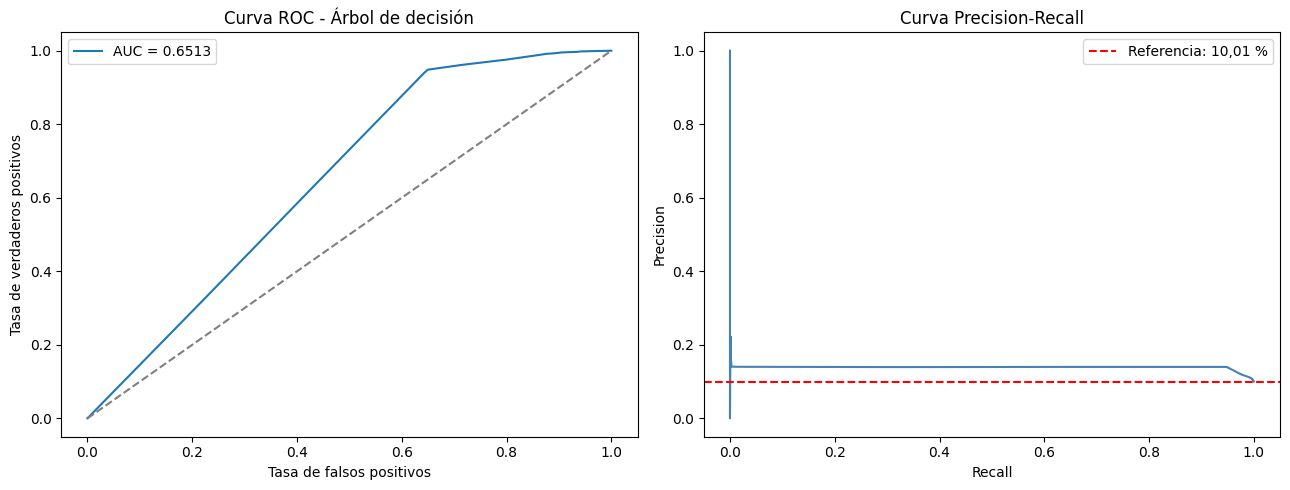

In [9]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc
)

# Probabilidades obtenidas mediante validación cruzada
probabilidades_cv = cross_val_predict(
    modelo_original,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Curva ROC
fpr, tpr, _ = roc_curve(y_train, probabilidades_cv)
roc_auc = auc(fpr, tpr)

# Curva Precision-Recall
precision, recall, _ = precision_recall_curve(
    y_train, probabilidades_cv
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - Árbol de decisión")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend()

# Precision-Recall
axes[1].plot(recall, precision, color="steelblue")
axes[1].axhline(
    y_train.mean(),
    linestyle="--",
    color="red",
    label="Referencia: 10,01 %"
)
axes[1].set_title("Curva Precision-Recall")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()


**Interpretación:** La curva ROC presenta un AUC de 0,6513, evidenciando una capacidad discriminativa limitada. La curva Precision-Recall muestra dificultades para identificar casos positivos con alta precisión, debido a la superposición entre las clases.

## 8. Optimización del umbral de clasificación

Se evalúan diferentes umbrales de probabilidad para identificar la configuración que maximiza el Accuracy, manteniendo independiente el conjunto de validación final.

In [10]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.base import clone

# División interna para ajustar el umbral
X_subtrain, X_umbral, y_subtrain, y_umbral = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=123
)

# Entrenar el árbol seleccionado
modelo_umbral = clone(modelo_original)
modelo_umbral.fit(X_subtrain, y_subtrain)

# Obtener probabilidades
prob_umbral = modelo_umbral.predict_proba(X_umbral)[:, 1]

# Probar distintos umbrales
umbrales = np.arange(0.05, 0.96, 0.01)

resultados_umbral = []

for umbral in umbrales:
    pred = (prob_umbral >= umbral).astype(int)

    resultados_umbral.append({
        "Umbral": round(umbral, 2),
        "Accuracy": accuracy_score(y_umbral, pred)
    })

df_umbral = pd.DataFrame(resultados_umbral)

# Mostrar los mejores resultados
display(
    df_umbral.sort_values(
        "Accuracy", ascending=False
    ).head(10).round(4)
)

# Mejor umbral
mejor_fila = df_umbral.loc[df_umbral["Accuracy"].idxmax()]

print("Mejor umbral:", mejor_fila["Umbral"])
print("Accuracy:", round(mejor_fila["Accuracy"], 4))


,Umbral,Accuracy
25,0.30,0.8999
24,0.29,0.8999
23,0.28,0.8999
19,0.24,0.8999
20,0.25,0.8999
21,0.26,0.8999
18,0.23,0.8999
15,0.20,0.8999
16,0.21,0.8999
17,0.22,0.8999


Mejor umbral: 0.19
Accuracy: 0.8999


**Interpretación:** La optimización del umbral no mejoró el Accuracy, que permaneció en 89,99 %. Varios umbrales produjeron resultados equivalentes, por lo que no se identificó una ventaja frente a la clasificación mayoritaria.

## 9. Evaluación final del modelo seleccionado

Se evalúa el árbol de decisión optimizado sobre el conjunto de validación reservado, utilizando Accuracy, Precision, Recall, F1-score y matriz de confusión.

EVALUACIÓN FINAL - ÁRBOL DE DECISIÓN
Accuracy: 0.8999
Precision: 0.0
Recall: 0.0
F1-score: 0.0


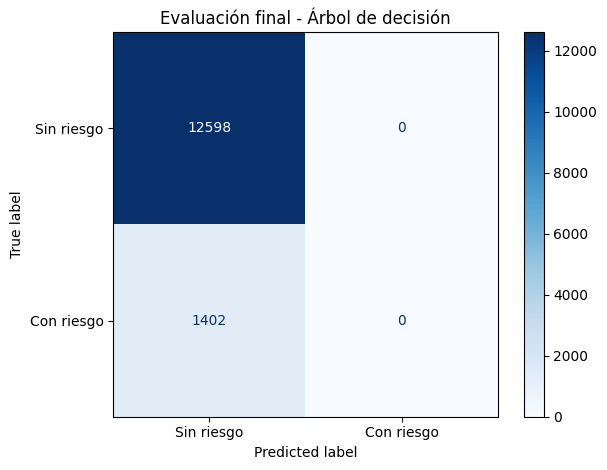

In [11]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Recuperar el mejor árbol de GridSearchCV
modelo_final = busqueda_arbol.best_estimator_

# Predicciones sobre validación final
y_pred_final = modelo_final.predict(X_val)

# Evaluar resultados
print("EVALUACIÓN FINAL - ÁRBOL DE DECISIÓN")
print("Accuracy:", round(accuracy_score(y_val, y_pred_final), 4))
print("Precision:", round(precision_score(y_val, y_pred_final, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_pred_final, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, y_pred_final, zero_division=0), 4))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_final,
    display_labels=["Sin riesgo", "Con riesgo"],
    cmap="Blues",
    values_format="d"
)

plt.title("Evaluación final - Árbol de decisión")
plt.tight_layout()
plt.show()


**Interpretación:** El árbol de decisión obtuvo un Accuracy del 89,99 %, pero no identificó ningún caso positivo. El resultado confirma que el modelo favorece exclusivamente la clase mayoritaria, por lo que su capacidad de detectar riesgo de desnutrición es insuficiente.

## 10. Modelo alternativo: CatBoost

Se evalúa CatBoost como modelo complementario para explorar relaciones no lineales y determinar si mejora el Accuracy respecto a los clasificadores tradicionales.

In [12]:

%pip install catboost


   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 1.0/100.2 MB 8.9 MB/s eta 0:00:12
   - -------------------------------------- 5.0/100.2 MB 14.7 MB/s eta 0:00:07
   --- ------------------------------------ 9.2/100.2 MB 16.0 MB/s eta 0:00:06
   ----- ---------------------------------- 12.8/100.2 MB 16.7 MB/s eta 0:00:06
   ------ --------------------------------- 16.5/100.2 MB 16.8 MB/s eta 0:00:05
   -------- ------------------------------- 21.0/100.2 MB 17.3 MB/s eta 0:00:05
   ---------- ----------------------------- 25.2/100.2 MB 17.7 MB/s eta 0:00:05
   ----------- ---------------------------- 29.4/100.2 MB 18.0 MB/s eta 0:00:04
   ------------- -------------------------- 33.3/100.2 MB 18.2 MB/s eta 0:00:04
   -------------- ------------------------- 36.2/100.2 MB 17.5 MB/s eta 0:00:04
   --------------- ------------------------ 38.0/100.2 MB 16.8 MB/s eta 0:00:04
   ---------------- ----------------------- 40.6/100.


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score
)

# Variables categóricas
cat_features = ["sexo", "region", "nivel_educacion_madre"]

# Configurar validación cruzada
cv_cat = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

resultados_catboost = []

# Entrenar un modelo nuevo en cada partición
for fold, (idx_train, idx_val) in enumerate(
    cv_cat.split(X_train, y_train), start=1
):

    X_tr = X_train.iloc[idx_train].copy()
    X_va = X_train.iloc[idx_val].copy()
    y_tr = y_train.iloc[idx_train]
    y_va = y_train.iloc[idx_val]

    # CatBoost maneja los valores faltantes numéricos
    modelo = CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function="Logloss",
        cat_features=cat_features,
        random_seed=42,
        verbose=False,
        thread_count=4,
        allow_writing_files=False
    )

    modelo.fit(X_tr, y_tr)

    pred = modelo.predict(X_va).astype(int).ravel()
    prob = modelo.predict_proba(X_va)[:, 1]

    resultados_catboost.append({
        "Partición": fold,
        "Accuracy": accuracy_score(y_va, pred),
        "ROC-AUC": roc_auc_score(y_va, prob),
        "Average Precision": average_precision_score(y_va, prob)
    })

# Resultados por partición
df_catboost = pd.DataFrame(resultados_catboost)

print("RESULTADOS POR PARTICIÓN")
display(df_catboost.round(4))

print("\nPROMEDIO DE VALIDACIÓN CRUZADA")
display(
    df_catboost[
        ["Accuracy", "ROC-AUC", "Average Precision"]
    ].mean().round(4)
)


RESULTADOS POR PARTICIÓN


,Partición,Accuracy,ROC-AUC,Average Precision
0,1,0.8998,0.6530,0.1407
1,2,0.8998,0.6545,0.1424
2,3,0.8998,0.6469,0.1357



PROMEDIO DE VALIDACIÓN CRUZADA


Accuracy             0.8998
ROC-AUC              0.6515
Average Precision    0.1396
dtype: float64

**Interpretación:** CatBoost alcanzó un Accuracy del 89,98 %, ROC-AUC de 0,6515 y Average Precision de 0,1396. Su rendimiento fue similar al árbol de decisión, sin superar la exactitud del modelo de referencia.

## 11. Generación de predicciones para Kaggle

Se entrena el clasificador seleccionado con todos los registros etiquetados y se generan predicciones para los 30.000 registros de prueba, respetando el formato de entrega de la competencia.

In [17]:

from sklearn.base import clone

# Entrenar el mejor árbol con todos los datos etiquetados
modelo_kaggle = clone(busqueda_arbol.best_estimator_)
modelo_kaggle.fit(X, y)

# Generar predicciones
predicciones_kaggle = modelo_kaggle.predict(X_test)

# Revisar distribución de predicciones
print("DISTRIBUCIÓN DE PREDICCIONES")
print(pd.Series(predicciones_kaggle).value_counts())

# Preparar archivo de entrega
entrega = submission.copy()

# Utilizar la columna objetivo del archivo de ejemplo
entrega["alerta_desnutricion"] = predicciones_kaggle.astype(int)

# Verificar dimensiones
print("\nDimensiones de entrega:", entrega.shape)
display(entrega.head())

# Guardar archivo CSV
entrega.to_csv("submission_kaggle.csv", index=False)

print("\nArchivo submission_kaggle.csv generado correctamente.")


DISTRIBUCIÓN DE PREDICCIONES
0    30000
Name: count, dtype: int64

Dimensiones de entrega: (30000, 2)


,ID,alerta_desnutricion
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0



Archivo submission_kaggle.csv generado correctamente.


**Interpretación:** El modelo generó 30.000 predicciones correspondientes a la clase sin riesgo. Aunque el archivo cumple con el formato de Kaggle, el clasificador no identifica casos positivos, por lo que se considera una solución de referencia y no una mejora predictiva demostrada.

## 12. Análisis de probabilidades y concentración del riesgo

Se analiza si los registros con mayor probabilidad estimada presentan una proporción superior de casos positivos, para evaluar la utilidad del modelo más allá del umbral de clasificación.

In [18]:

from sklearn.model_selection import cross_val_predict

# Probabilidades fuera de muestra mediante validación cruzada
probabilidades = cross_val_predict(
    modelo_original,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Tabla de análisis
analisis_riesgo = pd.DataFrame({
    "Probabilidad": probabilidades,
    "Riesgo_real": y_train.values
})

# Crear grupos según probabilidad
analisis_riesgo["Grupo"] = pd.qcut(
    analisis_riesgo["Probabilidad"].rank(method="first"),
    q=10,
    labels=False
) + 1

# Resumen por grupo
resumen_riesgo = (
    analisis_riesgo.groupby("Grupo")
    .agg(
        Registros=("Riesgo_real", "size"),
        Casos_riesgo=("Riesgo_real", "sum"),
        Probabilidad_media=("Probabilidad", "mean"),
        Porcentaje_riesgo=("Riesgo_real", "mean")
    )
)

resumen_riesgo["Porcentaje_riesgo"] *= 100

display(resumen_riesgo.round(2))


,Registros,Casos_riesgo,Probabilidad_media,Porcentaje_riesgo
Grupo,,,,
1,5600,40,0.00,0.71
2,5600,117,0.02,2.09
3,5600,105,0.02,1.88
4,5600,641,0.11,11.45
5,5600,794,0.14,14.18
6,5600,755,0.14,13.48
7,5600,802,0.14,14.32
8,5600,807,0.14,14.41
9,5600,773,0.14,13.80


**Interpretación:** Los grupos con mayores probabilidades concentran aproximadamente un 14 % de casos positivos, frente al 10,01 % general. Sin embargo, la separación entre clases sigue siendo insuficiente para mejorar el Accuracy mediante cambios simples del umbral.

## 13. Comparación entre entrenamiento y prueba

Se comparan las distribuciones de las variables entre ambos conjuntos para identificar posibles diferencias que puedan afectar la generalización del modelo.

In [19]:

# Comparar estadísticas de variables numéricas
comparacion_datos = pd.DataFrame({
    "Media entrenamiento": X[
        ["edad_meses", "peso_kg", "talla_cm"]
    ].mean(),
    "Media prueba": X_test[
        ["edad_meses", "peso_kg", "talla_cm"]
    ].mean(),
    "Mediana entrenamiento": X[
        ["edad_meses", "peso_kg", "talla_cm"]
    ].median(),
    "Mediana prueba": X_test[
        ["edad_meses", "peso_kg", "talla_cm"]
    ].median(),
    "Faltantes entrenamiento (%)": X[
        ["edad_meses", "peso_kg", "talla_cm"]
    ].isnull().mean() * 100,
    "Faltantes prueba (%)": X_test[
        ["edad_meses", "peso_kg", "talla_cm"]
    ].isnull().mean() * 100
})

display(comparacion_datos.round(2))

# Comparar distribución de región y educación
for columna in ["region", "nivel_educacion_madre", "sexo"]:
    print(f"\nDISTRIBUCIÓN: {columna}")

    tabla = pd.DataFrame({
        "Entrenamiento (%)":
            X[columna].value_counts(normalize=True) * 100,
        "Prueba (%)":
            X_test[columna].value_counts(normalize=True) * 100
    }).fillna(0)

    display(tabla.round(2))


,Media entrenamiento,Media prueba,Mediana entrenamiento,Mediana prueba,Faltantes entrenamiento (%),Faltantes prueba (%)
edad_meses,11.46,11.48,11.00,12.00,0.00,0.00
peso_kg,6.88,6.94,6.52,6.54,4.96,4.94
talla_cm,67.48,67.43,67.38,67.52,10.07,9.84



DISTRIBUCIÓN: region


,Entrenamiento (%),Prueba (%)
region,,
Amazonía,25.15,24.72
Costa,25.05,24.77
Insular,25.00,25.15
Sierra,24.80,25.36



DISTRIBUCIÓN: nivel_educacion_madre


,Entrenamiento (%),Prueba (%)
nivel_educacion_madre,,
Secundaria,44.98,45.03
Primaria,35.12,34.75
Superior,14.99,15.33
Sin escolaridad,4.91,4.89



DISTRIBUCIÓN: sexo


,Entrenamiento (%),Prueba (%)
sexo,,
F,50.26,50.22
M,49.74,49.78


**Interpretación:** Los conjuntos de entrenamiento y prueba presentan distribuciones similares en sus variables numéricas y categóricas, así como en los porcentajes de datos faltantes. No se identifican diferencias importantes que sugieran un cambio evidente en la distribución de las características.

## 16. Conclusiones

Se aplicaron técnicas de preprocesamiento, balanceo, validación cruzada y optimización de modelos de clasificación.

El mejor Accuracy obtenido fue del 89,99 %. Sin embargo, el clasificador no logró identificar casos positivos, debido a la limitada separación entre las clases con las variables disponibles.

El archivo final cumple con la estructura requerida por Kaggle y contiene 30.000 predicciones. Su desempeño definitivo deberá comprobarse mediante la evaluación oficial de la competencia.